# Structure-guided epitope masking of Hepatitis C glycoprotein E2

**Epitope masking:** occluding an immunodominant antigenic region with an N-linked glycan or a
conjugated polymer so that the response is redirected to subdominant regions.

Here, the region masked is the **βSW antigenic region** of the hepatitis C virus glycoprotein E2,
which dominates the antibody response at the expense of the subdominant front-layer (FRLY) region.
βSW is conventionally delimited by sequence, as E2 residues 486–517 and 536–565, but only about
half of the residues each βSW antibody contacts lie within those segments, so the surface to mask
is taken from antibody-bound structures instead. Analyzing a set of antigen–antibody complexes,
the residues contacted by *every* antibody in the set are defined as **common primary epitope
residues or CPER**, and those close to every antibody but contacted by none as **common secondary
epitope residues or CSER**.

We then compute, from an alignment of circulating strains, the frequency at every position of the
sequence feature required by the masking chemistry. For glycan masking this feature is an N-linked
sequon (N-X-S/T, X ≠ P), and for amine-directed conjugation it is a lysine. Positions where the
feature already occurs in circulating isolates are prioritized, on the reasoning that a variant
sampled by a replicating virus is compatible with E2 folding.

## Configuration

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from Bio import SeqIO
from Bio.PDB import NeighborSearch, PDBParser
from matplotlib.patches import Patch

DATA = Path("data")

# --- Structures ----
# Superposied all complexes onto a single antigen model before measuring contacts evaluates every interface against one antigen conformation,
# which removes differences in conformation, modelled range and numbering between depositions.
STRUCTURES = {
    "E1": DATA / "structures/E2_E1.pdb",
    "hcab17": DATA / "structures/E2_hcab17.pdb",
    "hcab44": DATA / "structures/E2_hcab44.pdb",
    "HEPC46": DATA / "structures/E2_HEPC46.pdb",
}
ANTIGEN_CHAIN = "C"

# Contact cutoffs, heavy atoms only.
PRIMARY_CUTOFF, SECONDARY_CUTOFF = 5.0, 10.0
EXCLUDED_FROM_CPER = [415]

# --- Alignment ----
ALIGNMENT = DATA / "E1E2_genotype1_alignment.fasta"
COLUMN_OFFSET = 192

# Range over which per-position frequencies are computed and plotted (the E2 ectodomain).
RANGE_FIRST, RANGE_LAST = 386, 645

COMPARISON_SEGMENTS = [(486, 517), (536, 565)]
COMPARISON_LABEL = "βSW segments"

# --- Plotting ---------------------------------------------------------------------------------
PRIMARY_COLOR, SECONDARY_COLOR, OTHER_COLOR = "#E69F00", "#008000", "#999999"

plt.rcParams["font.family"] = "sans-serif"
plt.rcParams["font.sans-serif"] = ["Arial", "Helvetica", "Liberation Sans", "DejaVu Sans"]
plt.rcParams["pdf.fonttype"] = 42
plt.rcParams["ps.fonttype"] = 42
plt.rcParams["svg.fonttype"] = "none"

## Part 1. Consensus epitope residues from the antibody complexes

For each complex, every antigen residue is classified by its minimum heavy-atom distance to the
antibody:

- **primary** — at least one heavy atom within 5 Å of an antibody heavy atom;
- **secondary** — not primary, but at least one heavy atom within 10 Å.


In [2]:
def contact_residues(pdb_path, antigen_chain=ANTIGEN_CHAIN,
                     primary_cutoff=PRIMARY_CUTOFF, secondary_cutoff=SECONDARY_CUTOFF):
    """Classify antigen residues as primary or secondary contacts of the antibody chains."""
    structure = PDBParser(QUIET=True).get_structure(pdb_path.stem, pdb_path)

    antigen, antibody = [], []
    for model in structure:
        for chain in model:
            (antigen if chain.id == antigen_chain else antibody).extend(chain.get_residues())

    heavy = lambda residues: [a for r in residues for a in r if not a.element.startswith("H")]
    neighbours = NeighborSearch(heavy(antibody))

    primary, secondary = set(), set()
    for residue in antigen:
        number = residue.get_id()[1]
        atoms = [a for a in residue if not a.element.startswith("H")]
        if any(neighbours.search(a.coord, primary_cutoff, level="A") for a in atoms):
            primary.add(number)
        elif any(neighbours.search(a.coord, secondary_cutoff, level="A") for a in atoms):
            secondary.add(number)
    return primary, secondary


contacts = {name: contact_residues(path) for name, path in STRUCTURES.items()}

in_comparison = lambda n: any(first <= n <= last for first, last in COMPARISON_SEGMENTS)

rows = []
for name, (primary, secondary) in contacts.items():
    row = {"antibody": name, "primary": len(primary), "secondary": len(secondary)}
    if COMPARISON_SEGMENTS:
        inside = {n for n in primary if in_comparison(n)}
        row[f"primary in {COMPARISON_LABEL}"] = len(inside)
        row["% inside"] = round(100 * len(inside) / len(primary), 1)
    rows.append(row)
print(pd.DataFrame(rows).to_string(index=False))

antibody  primary  secondary  primary in βSW segments  % inside
      E1       31         51                       15      48.4
  hcab17       29         51                       13      44.8
  hcab44       29         57                       12      41.4
  HEPC46       28         52                       13      46.4


In [3]:
common_primary = sorted(set.intersection(*(p for p, _ in contacts.values())))
common_secondary = sorted(set.intersection(*(s for _, s in contacts.values())))

# In this example, residue 415 meets the primary-contact criterion in all four complexes but is
# excluded: it lies in antigenic site 412 (AS412), a region distinct from βSW, and is the second
# modelled residue of the antigen chain (which begins at 414), so its apparent contact with every
# antibody is most probably an artefact of superposing four antibodies onto one truncated antigen.
# The unfiltered intersection is printed here so the effect of the exclusion is visible.
print(f"Common primary residues, all {len(contacts)} complexes ({len(common_primary)}):")
print(f"  {common_primary}")
if EXCLUDED_FROM_CPER:
    print(f"Excluded: {EXCLUDED_FROM_CPER} (see comment above)")

CPER = [n for n in common_primary if n not in EXCLUDED_FROM_CPER]
CSER = common_secondary

print(f"\nCPER ({len(CPER)}): {CPER}")
print(f"CSER ({len(CSER)}): {CSER}")

Common primary residues, all 4 complexes (16):
  [415, 474, 538, 540, 541, 542, 543, 545, 546, 547, 548, 549, 567, 596, 634, 636]
Excluded: [415] (see comment above)

CPER (15): [474, 538, 540, 541, 542, 543, 545, 546, 547, 548, 549, 567, 596, 634, 636]
CSER (23): [476, 495, 506, 508, 509, 512, 513, 517, 520, 536, 537, 539, 550, 551, 565, 566, 593, 594, 598, 599, 632, 637, 638]


## Part 2. Where the required sequence feature already occurs in circulating strains

Introducing a sequon or a conjugation handle into a folded, disulfide-rich glycoprotein risks
impairing folding, secretion or antigenicity. Restricting candidate positions to those where the
required feature is already sampled by circulating virus is a cheap prior filter.

In [4]:
records = list(SeqIO.parse(ALIGNMENT, "fasta"))
sequences = [str(record.seq) for record in records]

print(f"{len(sequences)} sequences, alignment length {len(sequences[0])}")

subtypes = pd.Series([r.id.split(".")[0].replace("AL_", "") for r in records]).value_counts()
print("\nSubtype composition:")
print(subtypes.to_string())

11070 sequences, alignment length 555

Subtype composition:
1a    9310
1b    1746
1c       4
1g       4
1h       3
1e       2
1i       1


In [5]:
def sequon_frequency(sequences, offset=COLUMN_OFFSET):
    """Count sequences carrying an N-X-S/T sequon (X != P) at each position.

    The position reported is that of the first residue of the sequon, which carries the glycan.
    """
    counts = {}
    for sequence in sequences:
        for column in range(len(sequence) - 2):
            asn, x, ser_thr = sequence[column : column + 3]
            if asn == "N" and x != "P" and ser_thr in {"S", "T"}:
                counts[column + offset] = counts.get(column + offset, 0) + 1
    return counts


def residue_frequency(sequences, residue="K", offset=COLUMN_OFFSET):
    """Count sequences carrying a given residue at each position."""
    counts = {}
    for sequence in sequences:
        for column, found in enumerate(sequence):
            if found == residue:
                counts[column + offset] = counts.get(column + offset, 0) + 1
    return counts


def frequency_table(counts, n_sequences, first=RANGE_FIRST, last=RANGE_LAST):
    """Non-zero positions in range, as percentages, annotated with CPER/CSER membership."""
    frame = pd.DataFrame(sorted(counts.items()), columns=["position", "n_sequences"])
    frame = frame[frame["position"].between(first, last)].copy()
    frame["percent"] = 100 * frame["n_sequences"] / n_sequences
    frame["region"] = np.where(
        frame["position"].isin(CPER), "CPER", np.where(frame["position"].isin(CSER), "CSER", "other")
    )
    return frame.reset_index(drop=True)


sequons = frequency_table(sequon_frequency(sequences), len(sequences))
lysines = frequency_table(residue_frequency(sequences, "K"), len(sequences))

print("Permissive positions — the feature is already present in at least one strain\n")
for label, frame in [("N-linked sequon (glycan masking)", sequons),
                     ("Lysine (amine-directed conjugation)", lysines)]:
    hits = frame[frame["region"] != "other"]
    print(f"{label}:")
    print(hits.to_string(index=False, float_format=lambda v: f"{v:.3f}"))
    print()

Permissive positions — the feature is already present in at least one strain

N-linked sequon (glycan masking):
 position  n_sequences  percent region
      476         8902   80.416   CSER
      520            2    0.018   CSER
      540        10764   97.236   CPER
      548            3    0.027   CPER

Lysine (amine-directed conjugation):
 position  n_sequences  percent region
      476          314    2.836   CSER
      495            1    0.009   CSER
      542            2    0.018   CPER
      543            2    0.018   CPER
      596         1694   15.303   CPER



### Sequon frequency across the antigen

Only positions with a non-zero frequency are shown, as evenly spaced categories on a log scale, so
that rare positions remain legible beside near-universal ones. CPER are orange, CSER green.

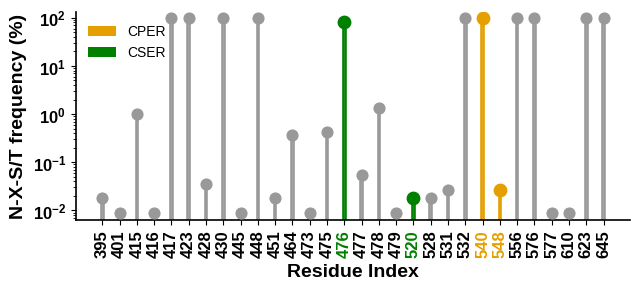

In [6]:
def lollipop_panel(
    frame,
    ylabel,
    figsize=(13, 3.25),
    label_fontsize=16,
    tick_fontsize=11,
    marker_size=70,
    highlight_marker_size=100,
    ylim_floor_factor=0.5,
    legend_fontsize=12,
):
    """Categorical lollipop panel of per-position frequencies, coloured by CPER/CSER membership."""
    frame = frame[frame["percent"] > 0].sort_values("position")
    positions = frame["position"].to_numpy()
    percent = frame["percent"].to_numpy()
    x = np.arange(len(positions))

    is_cper = np.isin(positions, CPER)
    is_cser = np.isin(positions, CSER)
    is_other = ~(is_cper | is_cser)
    colors = np.where(is_cper, PRIMARY_COLOR, np.where(is_cser, SECONDARY_COLOR, OTHER_COLOR))

    fig, ax = plt.subplots(figsize=figsize)
    ax.bar(x, percent, width=0.15, color=colors, edgecolor=colors, linewidth=1.3, alpha=0.9, zorder=1)
    ax.scatter(x[is_other], percent[is_other], s=marker_size, color=OTHER_COLOR, zorder=3)
    ax.scatter(x[is_cper], percent[is_cper], s=highlight_marker_size, color=PRIMARY_COLOR, zorder=4)
    ax.scatter(x[is_cser], percent[is_cser], s=highlight_marker_size, color=SECONDARY_COLOR, zorder=4)

    ax.set_xlabel("Residue Index", fontsize=label_fontsize, fontweight="bold")
    ax.set_ylabel(ylabel, fontsize=label_fontsize, fontweight="bold")
    ax.set_yscale("log")
    ax.set_ylim(max(percent.min() * ylim_floor_factor, 1e-4), percent.max() * 1.3)

    ax.set_xticks(x)
    ax.set_xticklabels(positions, rotation=90, fontsize=tick_fontsize, fontweight="bold")
    ax.tick_params(axis="y", labelsize=12)
    plt.setp(ax.get_yticklabels(), fontweight="bold")
    for tick, position in zip(ax.get_xticklabels(), positions):
        if position in CPER:
            tick.set_color(PRIMARY_COLOR)
        elif position in CSER:
            tick.set_color(SECONDARY_COLOR)

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["left"].set_linewidth(1.2)
    ax.spines["bottom"].set_linewidth(1.2)
    ax.legend(
        handles=[
            Patch(facecolor=PRIMARY_COLOR, edgecolor="none", label="CPER"),
            Patch(facecolor=SECONDARY_COLOR, edgecolor="none", label="CSER"),
        ],
        fontsize=legend_fontsize,
        loc="upper left",
        frameon=False,
    )
    plt.tight_layout()
    return fig, ax


lollipop_panel(
    sequons,
    ylabel="N-X-S/T frequency (%)",
    figsize=(6.5, 3),
    label_fontsize=14,
    tick_fontsize=12,
    marker_size=60,
    highlight_marker_size=80,
    ylim_floor_factor=0.7,
    legend_fontsize=10,
)
plt.show()

### Lysine frequency across the antigen

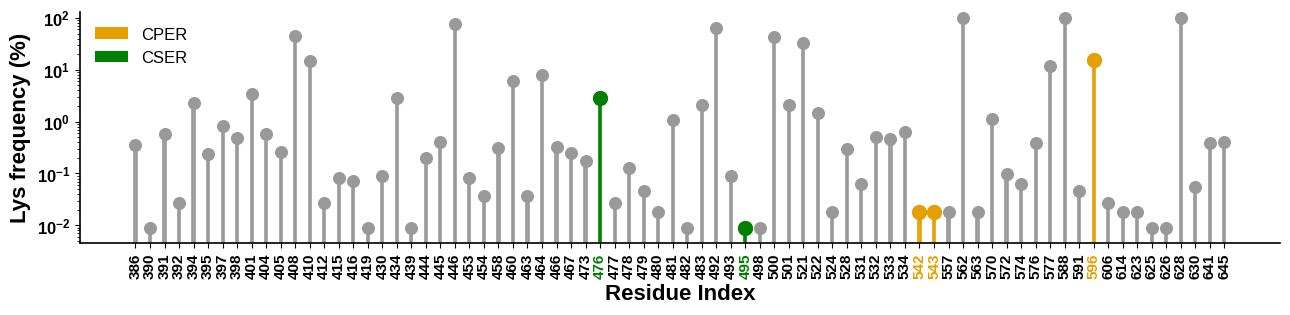

In [7]:
lollipop_panel(lysines, ylabel="Lys frequency (%)")
plt.show()